# Tutorial 10 — Recovery rheology

Recovery rheology splits the total shear strain of a viscoelastic material
into a recoverable (elastic) part and an unrecoverable (viscous or plastic)
part (Lee et al., 2019),

$$
\gamma_\mathrm{tot} = \gamma_\mathrm{rec} + \gamma_\mathrm{unrec}.
$$

The recoverable strain is measured directly: the imposed deformation is
interrupted, the stress is set to zero, and the strain that returns is
recorded. Each component then defines its own material function, the
recoverable modulus $G_\mathrm{rec} = \sigma/\gamma_\mathrm{rec}$ and the
flow viscosity $\eta_\mathrm{flow} = \sigma/\dot\gamma_\mathrm{unrec}$
(Singh et al., 2021). This separates solid-like from fluid-like contributions
that conventional moduli mix, for example across a yield transition (Donley
et al., 2020).

`RecoveryRheology` analyses [Anton Paar](https://www.anton-paar.com/us-en/)
[RheoCompass](https://www.anton-paar.com/us-en/products/details/rheometer-software-rheocompass/)
exports with two protocols:

- `method="oscillatory"` (oscillatory recovery): oscillations interrupted by
  zero-stress recovery steps. Forward and reverse runs with opposite strain
  amplitude are averaged as $(A - B)/2$, which keeps the response that is odd
  in strain and cancels drift that does not change sign.
- `method="step"` (step-function recovery): strain- or stress-controlled
  deformation steps of increasing duration, each followed by a zero-stress
  recovery step.

All recovery data in this tutorial are full resolution.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt

from hermes_rheo import read_file
from hermes_rheo.file_readers.rheo_compass_csv import RheoCompassReader
from hermes_rheo.transforms.recovery_rheology import (
    RecoveryRheology,
    batch_oscillatory_recovery,
    plot_decomposed_moduli,
)
from hermes_rheo.visualization import use_science_style

use_science_style()
DATA = Path("tutorial_data")

## Oscillatory recovery

The Fourier component of the averaged stress at the test frequency $\omega$
gives the conventional $G'$ and $G''$. The transform then reconstructs a full
period of the strain, recoverable strain and stress, and computes
cycle-averaged energies for each strain component
$x \in \{\mathrm{tot}, \mathrm{rec}, \mathrm{unrec}\}$:

$$
G'_x = \frac{2\,\langle \gamma_x\,\sigma \rangle}{\gamma_0^2},
\qquad
G''_x = \frac{2\,\langle \dot\gamma_x\,\sigma \rangle}{(\omega\,\gamma_0)^2},
$$

where $\gamma_0$ is the total-strain amplitude. $G'_\mathrm{solid} = G'_\mathrm{rec}$
is the energy stored elastically, $G''_\mathrm{solid} = G''_\mathrm{rec}$ the
energy dissipated by recoverable deformation, and
$G''_\mathrm{fluid} = G''_\mathrm{unrec}$ the energy dissipated by flow.
Supply the known `omega` (rad/s); otherwise it is estimated from the data.

Lissajous figures plot the stress against total strain, recoverable strain and
unrecoverable strain rate. A stress–$\gamma_\mathrm{rec}$ loop that collapses
to a straight line indicates purely elastic recovery, while the
stress–$\dot\gamma_\mathrm{unrec}$ loop shows the fluid contribution.

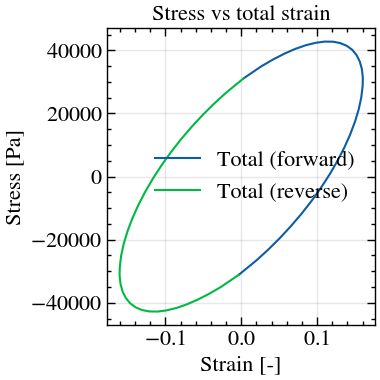

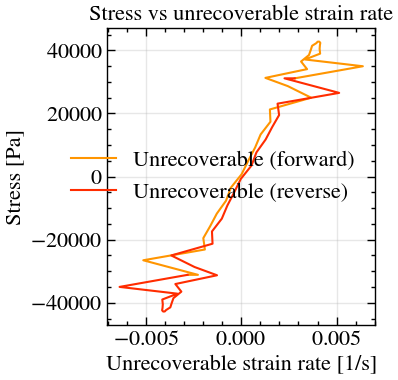

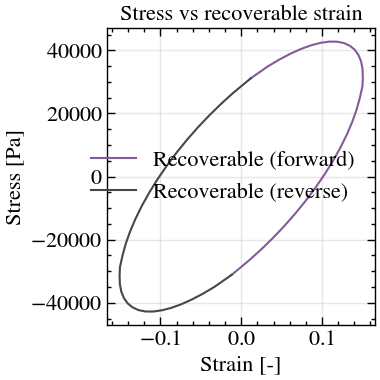

In [2]:
oscillatory = read_file(DATA / "mcr702e_rheocompass_recovery_oscillatory.csv",
                        file_reader=RheoCompassReader, create_composite_dataset=True)

oscillatory_recovery = RecoveryRheology(method="oscillatory", omega=0.316)(oscillatory).result
figures, axes = oscillatory_recovery.plot_lissajous(figsize=(4, 4))
plt.show()

### Amplitude series

`batch_oscillatory_recovery` applies the analysis to every file in a folder;
here, one polymer melt at the same temperature and $\omega = 0.316$ rad/s for
strain amplitudes from 1 % to 631 %. In the linear regime the decomposed
moduli are constant and $G'_\mathrm{solid}$ dominates. At large amplitudes,
$G'_\mathrm{solid}$ decreases while $G''_\mathrm{fluid}$ grows, showing
the transition from recoverable deformation to flow. Pass `export_dir=` to
also write the per-file Excel results and Lissajous figures.

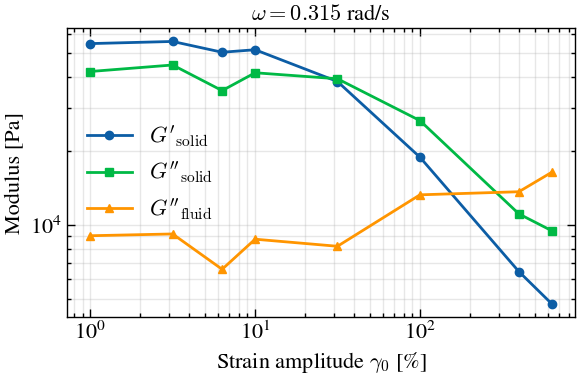

In [3]:
amplitude_series = batch_oscillatory_recovery(DATA / "recovery_series", n_osc=2, diff_state=4, k_step=1)
fig, ax = plot_decomposed_moduli(amplitude_series, x_axis="strain")
plt.show()

## Step-function recovery

Each deformation step is followed by recovery at zero stress. The strain left
after recovery is $\gamma_\mathrm{unrec}$, and the recovered strain is

$$
\gamma_\mathrm{rec}(t_\mathrm{r}) = \gamma_\mathrm{tot}(t_\mathrm{exp}) - \gamma(t_\mathrm{r}),
$$

where $t_\mathrm{exp}$ is the end of the deformation and $t_\mathrm{r}$ the
recovery time. Increasing the step duration maps how the recoverable and
unrecoverable strains build up during the deformation. `plot_step_results`
shows the three strains against experimental time; `plot_transient` shows the
recovered strain against recovery time for each step. The same analysis
applies to any deformation step; the three examples below use step strain,
creep and start-up shear.

### Step strain

A strain of 2000 % ($\gamma_\mathrm{tot} = 20$) is held for increasing
durations at 100 °C. The total strain is fixed, so the analysis shows how it
is partitioned: as the stress relaxes during longer holds, more of the imposed
strain becomes unrecoverable and less is recovered.

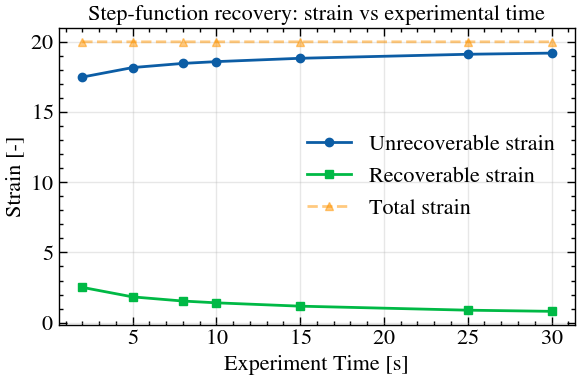

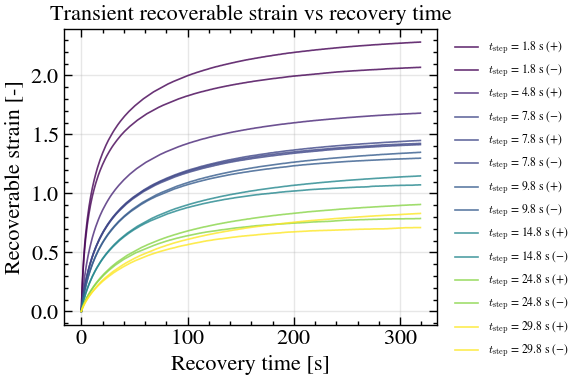

In [4]:
step_strain_data = read_file(DATA / "mcr702e_rheocompass_step_strain_recovery.csv",
                            file_reader=RheoCompassReader, create_composite_dataset=True)

step_strain_recovery = RecoveryRheology(method="step")(step_strain_data).result
fig, ax = step_strain_recovery.plot_step_results(figsize=(6, 4))
plt.show()
fig, ax = step_strain_recovery.plot_transient(figsize=(6, 4), logx=False)
plt.show()

### Creep

A constant stress of 100 Pa is applied for increasing durations at 70 °C. The
total strain grows with the creep time; at this stress most of it is
recovered, and the unrecoverable strain, the flow contribution, builds up
slowly.

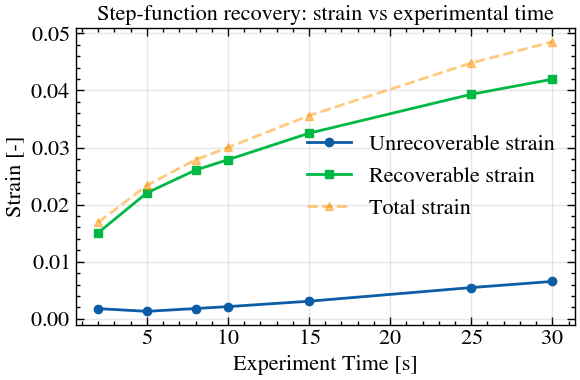

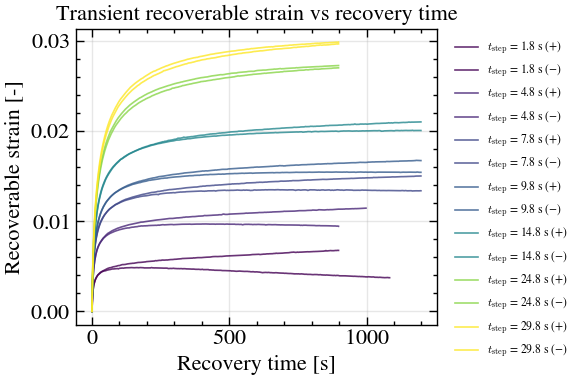

In [5]:
creep_data = read_file(DATA / "mcr702e_rheocompass_creep_recovery.csv",
                      file_reader=RheoCompassReader, create_composite_dataset=True)

creep_recovery = RecoveryRheology(method="step")(creep_data).result
fig, ax = creep_recovery.plot_step_results(figsize=(6, 4))
plt.show()
fig, ax = creep_recovery.plot_transient(figsize=(6, 4), logx=False)
plt.show()

### Start-up shear

A constant shear rate of 1 s$^{-1}$ is applied for increasing durations at
70 °C, so the total strain grows linearly with time. The recoverable strain
saturates as the material approaches steady flow, after which the additional
strain is unrecoverable.

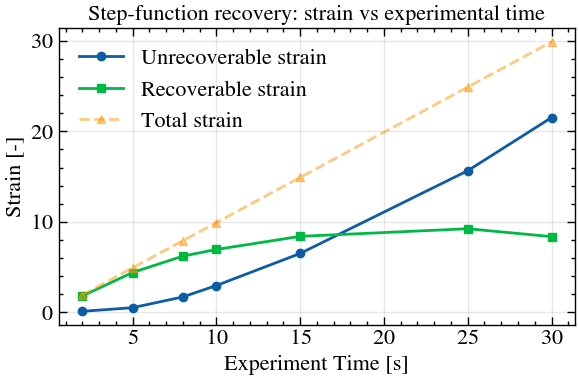

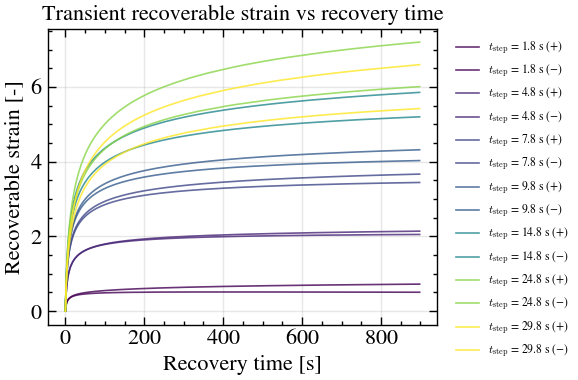

In [6]:
startup_shear_data = read_file(DATA / "mcr702e_rheocompass_startup_shear_recovery.csv",
                              file_reader=RheoCompassReader, create_composite_dataset=True)

startup_shear_recovery = RecoveryRheology(method="step")(startup_shear_data).result
fig, ax = startup_shear_recovery.plot_step_results(figsize=(6, 4))
plt.show()
fig, ax = startup_shear_recovery.plot_transient(figsize=(6, 4), logx=False)
plt.show()

Both result objects export the transient data and moduli with `to_excel(path)`.

## References

- Lee, J. C.-W., Weigandt, K. M., Kelley, E. G. and Rogers, S. A.,
  *Structure–Property Relationships via Recovery Rheology in Viscoelastic
  Materials*, *Physical Review Letters* **122**, 248003 (2019).
  DOI: [10.1103/PhysRevLett.122.248003](https://doi.org/10.1103/PhysRevLett.122.248003).
- Donley, G. J., Singh, P. K., Shetty, A. and Rogers, S. A., *Elucidating the
  G″ overshoot in soft materials with a yield transition via a time-resolved
  experimental strain decomposition*, *Proceedings of the National Academy of
  Sciences* **117**, 21945–21952 (2020).
  DOI: [10.1073/pnas.2003869117](https://doi.org/10.1073/pnas.2003869117).
- Singh, P. K., Lee, J. C.-W., Patankar, K. A. and Rogers, S. A., *Revisiting
  the basis of transient rheological material functions: Insights from
  recoverable strain measurements*, *Journal of Rheology* **65**, 129–144
  (2021). DOI: [10.1122/8.0000154](https://doi.org/10.1122/8.0000154).
- Shi, J. and Rogers, S. A., *The benefits of a formalism built on recovery:
  Theory, experiments, and modeling*, *Journal of Non-Newtonian Fluid
  Mechanics* **321**, 105113 (2023).
  DOI: [10.1016/j.jnnfm.2023.105113](https://doi.org/10.1016/j.jnnfm.2023.105113).